# Find patterns in historical recalls

The analysis covers 6,637 reconciled CPSC recall notices. Each comparison uses records with the necessary fields. We look for recurring category–hazard combinations, then group products by name and appearance and examine the hazard labels afterward.

The hazard label field (`hazard_classification`) contains RECALL-MM annotations such as FALLING. The recall description (`recall_description`) explains why the product was recalled. A phrase such as “hinge cracking” describes a failure mechanism. A visible structure cue is extracted from `visual_product_description`, and the verbatim CPSC risk statement is preserved in `official.hazard_description`.

## 1 Verify recall notices

A source record is a row in RECALL-MM. A recall notice is one CPSC announcement, identified by its public recall number. The reconciliation summary and source-row ledger document how the rows were assigned.

In [1]:
import os
import re
import sys
from itertools import combinations, product
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from scipy.stats import chi2_contingency, fisher_exact, random_table
from sklearn.feature_extraction.text import TfidfVectorizer

TEXT_NAMES = {
    "product_name": "Product name",
    "visual_product_description": "Visual product description",
    "recall_description": "Recall description",
    "remedies": "Remedy text",
}
LABEL_NAMES = {
    "product_classification": "Product category",
    "hazard_classification": "Hazard label",
    "remedies_classification": "Remedy label",
}
MODEL_ID = "sentence-transformers/all-MiniLM-L6-v2"
MODEL_SOURCE = os.environ.get("RECALL_MINILM_PATH", MODEL_ID)
PERMUTATIONS = 1999
SEED = 2026

project_dir = next((
    base for base in (Path.cwd(), Path.cwd().parent, Path.cwd() / "DM-project")
    if (base / "recall_audit/scripts/project_data.py").is_file()
), None)
if project_dir is None:
    raise FileNotFoundError("Start the notebook from the project, recall_audit, or their parent directory.")
sys.path.insert(0, str(project_dir / "recall_audit/scripts"))
from association_rules import category_hazard_rules, highlight_rules
from product_features import announcement_groups, embed_variants, normalized_official_names, product_text_variants
from project_data import load_notice_audit, load_notices

dataset = pd.DataFrame(load_notices())
summary, audit_rows = load_notice_audit()
ledger = pd.DataFrame(audit_rows)

assert dataset["recall_number"].is_unique
assert len(ledger) == summary["raw_rows"] and ledger["source_row"].is_unique
assert ledger["official_number"].notna().sum() == summary["mapped_rows"]

summary_columns = {
    "raw_rows": "Source rows",
    "repeated_source_id_groups": "Source ID groups with multiple rows",
    "mapped_rows": "Source rows matched to official notices",
    "unresolved_rows": "Source rows with ambiguous notice matches",
    "officially_identified_non_recall_rows": "Settlement news releases without a recall number",
    "corrected_announcements": "Reconciled official notices",
    "announcements_with_multiple_rows": "Notices that combine multiple source rows",
    "announcements_with_multiple_visual_descriptions": "Notices retaining multiple visual descriptions",
    "confirmed_split_source_groups": "Source ID groups split across official notices",
    "changed_internal_id_rows": "Rows assigned a different internal ID",
    "changed_date_rows": "Rows with a corrected date",
    "changed_quantity_rows": "Rows with a different count in the official notice",
    "quantity_unknown_announcements": "Notices without a comparable item count",
    "visible_remedy_label_disagreements": "Notices with different official and derived remedy labels",
}
display(pd.Series({caption: summary[key] for key, caption in summary_columns.items()}, name="Count").to_frame())

examples = ledger.loc[ledger["source_recall_number"].isin([607, 1177, 1412]), [
    "source_row", "source_recall_number", "source_recall_date", "official_number",
    "official_date", "official_url", "review_note",
]]
with pd.option_context("display.max_colwidth", 110):
    display(examples)
display(dataset.loc[dataset["recall_number"].eq("13-231"), [
    "recall_number", "source_rows", "visual_product_description",
]])

,Count
Source rows,6874
Source ID groups with multiple rows,248
Source rows matched to official notices,6835
Source rows with ambiguous notice matches,38
Settlement news releases without a recall number,1
Reconciled official notices,6637
Notices that combine multiple source rows,126
Notices retaining multiple visual descriptions,121
Source ID groups split across official notices,128
Rows assigned a different internal ID,197


,source_row,source_recall_number,source_recall_date,official_number,official_date,official_url,review_note
433,434,607,2011-02-23,11-143,2011-02-23,https://www.cpsc.gov/Recalls/2011/Jogging-Strollers-Recalled-by-BOB-Trailers-Due-to-Strangulation-Hazard,
663,664,607,2011-02-23,12-006,2011-10-11,https://www.cpsc.gov/Recalls/2012/Jogging-Strollers-Recalled-by-BOB-Trailers-Due-to-Choking-Hazard,"B.O.B. canopy embroidery backing patch, distinct from the earlier drawstring notice."
1035,1036,1177,2012-02-08,16-748,2016-05-26,https://www.cpsc.gov/Recalls/2016/Curry-and-Company-Recalls-Chandeliers,Eight-light Currey/Ethan Allen model and verbatim mounting-loop impact hazard.
1171,1172,1177,2012-02-08,12-719,2012-02-08,https://www.cpsc.gov/Recalls/2012/Spectrum-Home-Furnishings-Recalls-Chandeliers-Due-to-Injury-Hazard,"Verbatim Spectrum mounting-loop hazard, matching notice date and 165-unit count."
1690,1691,1412,2013-06-27,13-231,2013-06-27,https://www.cpsc.gov/Recalls/2013/Stile-Products-Recalls-Tern-Folding-Bicycles,"Tern frame hinge, same date and 175-unit count as row 5654."
5442,5443,1177,2012-02-08,17-184,2017-07-05,https://www.cpsc.gov/Recalls/2017/Lumicentro-Internacional-with-Home-Depot-Recalls-Crystal-Chandeliers,Verbatim halogen bulb melting hazard in the Lumicentro recall.
5653,5654,1412,2013-06-27,13-231,2013-06-27,https://www.cpsc.gov/Recalls/2013/Stile-Products-Recalls-Tern-Folding-Bicycles,"Tern frame hinge, same date and 175-unit count as row 1691."


,recall_number,source_rows,visual_product_description
3662,13-231,"[1691, 5654]",This bicycle features a compact folding design...


Tern notice 13-231 keeps two appearance variants on one notice. The three rows sharing source ID 1177 instead match three separate notices. Expanded or reissued notices keep their own number, date and scope. [Tern](https://www.cpsc.gov/Recalls/2013/Stile-Products-Recalls-Tern-Folding-Bicycles) · [Spectrum](https://www.cpsc.gov/Recalls/2012/spectrum-home-furnishings-recalls-chandeliers-due-to-injury-hazard) · [Currey](https://www.cpsc.gov/Recalls/2016/Curry-and-Company-Recalls-Chandeliers) · [Lumicentro](https://www.cpsc.gov/Recalls/2017/lumicentro-internacional-with-home-depot-recalls-crystal-chandeliers)

### Product variants and related notices

Combine rows with the same official recall number. Keep distinct official notices as separate observations. Brompton recalls 21-116 and 22-155 describe different mechanisms in the same product line. They are assigned to the same evaluation group. Explicitly linked Carrier notices are grouped even though their official product names differ. Repeated names and expansion wording are useful flags for review. They do not give an exact model-level count. [Brompton 21-116](https://www.cpsc.gov/Recalls/2021/Brompton-Bicycle-Recalls-Electric-Folding-Bicycles-Due-to-Fall-and-Injury-Hazards) · [Brompton 22-155](https://www.cpsc.gov/Recalls/2022/Brompton-Bicycle-Recalls-Foldable-Electric-Bicycles-Due-to-Crash-and-Injury-Hazards) · [Carrier 17-094](https://www.cpsc.gov/Recalls/2017/carrier-expands-recall-of-packaged-terminal-air-conditioners-and-heat-pumps)

In [2]:
official_names = normalized_official_names(dataset)
name_sizes = official_names[official_names.ne("")].value_counts()
real_followup_words = r"\b(?:expand(?:s|ed|ing)?|expansion|re[- ]?announc\w+|re[- ]?issu\w+)\b"
marked_followup = dataset["official"].map(lambda item: item["title"]).str.contains(
    real_followup_words, flags=re.I, regex=True, na=False
)
display(pd.Series({
    "Official notices combining multiple source rows": summary["announcements_with_multiple_rows"],
    "Official product names with multiple notices": int(name_sizes.gt(1).sum()),
    "Notices in those same-name groups": int(name_sizes[name_sizes.gt(1)].sum()),
    "Titles mentioning expansion or reannouncement": int(marked_followup.sum()),
}, name="Count").to_frame())
sample_notices = dataset[dataset["recall_number"].isin(["08-073", "17-094", "21-116", "22-155"])]
display(sample_notices.assign(
    Official_product_name=sample_notices["official"].map(lambda item: item["product_name"]),
    Official_hazard_description=sample_notices["official"].map(lambda item: item["hazard_description"]),
    Split_group=announcement_groups(dataset).loc[sample_notices.index],
)[["recall_number", "recall_date", "Official_product_name", "Official_hazard_description", "Split_group"]])

,Count
Official notices combining multiple source rows,126
Official product names with multiple notices,195
Notices in those same-name groups,503
Titles mentioning expansion or reannouncement,87


,recall_number,recall_date,Official_product_name,Official_hazard_description,Split_group
1914,08-073,2007-11-07,Packaged Terminal Air Conditioners (PTAC) and ...,"An electric heater in the unit can break, posi...",series:08-073
4669,17-094,2017-02-23,Packaged Terminal Air Conditioners (PTAC) and ...,The power cord plug of the packaged terminal a...,series:08-073
5653,21-116,2021-04-21,Brompton Electric Folding Bicycles,"Due to a software malfunction, the electric sy...",name:brompton electric folding bicycles
5906,22-155,2022-06-09,Brompton Electric Folding Bicycles,The mudguard is positioned too close to the fr...,name:brompton electric folding bicycles


In [3]:
pending = ledger.loc[
    ledger["official_number"].isna()
    & ledger["decision"].ne("official_settlement_without_recall_number")
].copy()
pending["Candidate notice numbers"] = pending["candidate_evidence"].map(
    lambda candidates: " / ".join(candidate["number"] for candidate in candidates)
)
with pd.option_context("display.max_rows", None):
    display(pending[["source_row", "source_recall_number", "source_product_name", "Candidate notice numbers"]])

,source_row,source_recall_number,source_product_name,Candidate notice numbers
96,97,9092,Children's Robes,23-113 / 23-110 / 23-112
938,939,3325,Hooded Sweatshirts,09-269 / 10-144 / 09-274
944,945,98,plastic tree step that attaches to a tree with...,11-024 / 10-236 / 10-006
971,972,98,Plastic tree step with a nylon strap and metal...,10-101 / 11-024 / 10-236
977,978,3206,Children's Hooded Sweatshirts with Drawstrings,10-053 / 10-170 / 10-204
1068,1069,66,Roman Shades and Roll-Up Blinds,10-066 / 10-067 / 10-068
1166,1167,630,Bicycles with front disc brakes and quick-rele...,15-253 / 15-118 / 15-221
1272,1273,7785,Self-balancing scooters/hoverboards,16-208 / 16-210 / 16-209
1678,1679,3109,All-terrain vehicles (ATVs),08-580 / 08-193 / 05-583
2114,2115,76,Roman shades with exposed inner cords,10-074 / 10-068 / 10-072


## Common hazard labels by product category

Apriori counts co-occurrences of RECALL-MM product categories and hazard labels. Each notice can contribute all of its labels. Keep pairs with at least 30 joint notices. Confidence is the share of notices in the category that carry the label. Lift divides that share by the overall share. The displayed rule for each category has confidence of at least 20%, lift above one and the highest eligible lift among specific hazard labels. The evaluation notebook checks whether these patterns recur on held-out notices.

In [4]:
from sklearn.preprocessing import MultiLabelBinarizer


def boolean_tags(column):
    encoder = MultiLabelBinarizer()
    return pd.DataFrame(encoder.fit_transform(column).astype(bool),
                        index=column.index, columns=encoder.classes_)


category_indicators = boolean_tags(dataset["product_classification"])
hazard_indicators = boolean_tags(dataset["hazard_classification"])
all_category_rules = category_hazard_rules(category_indicators, hazard_indicators)
priority_rules = highlight_rules(all_category_rules)
display(priority_rules.round(3))
print(f"Category–hazard pairs co-occurring in at least 30 notices: {len(all_category_rules)}.")

,Product category,Hazard label,Category notices,Joint notices,Support,Category share,Overall share,Lift
42,TRANSPORTATION,CRASH,769,352,0.053,0.458,0.064,7.115
32,TOOLS_HARDWARE,CUTS,346,123,0.019,0.355,0.067,5.326
22,OTHER,POISONING,368,132,0.020,0.359,0.094,3.834
10,FURNITURE,FALLING,454,271,0.041,0.597,0.156,3.817
3,CLOTHING_ACCESSORIES,CHOKING,425,203,0.031,0.478,0.142,3.372
29,SPORTS_RECREATION,IMPACT,619,148,0.022,0.239,0.073,3.285
0,BABY_PRODUCTS,CHOKING,402,185,0.028,0.460,0.142,3.249
36,TOYS_CHILDREN,CHOKING,1168,493,0.074,0.422,0.142,2.980
6,ELECTRICAL,FIRE,594,374,0.056,0.630,0.248,2.534
16,HOME_APPLIANCES,FIRE,1174,621,0.094,0.529,0.248,2.129


## 2 Measure associations between fields

Use a chi-square statistic and Cramér’s V for paired categorical fields. Use paired text similarity for two text fields, and grouped embedding variance (R²) for text versus a category. The 21 field-level comparisons use Holm adjustment.

In [5]:
def holm(p_values):
    """Controls the family-wise error rate over the announced comparisons."""
    p = np.asarray(p_values, dtype=float)
    order = np.argsort(p)
    adjusted = np.empty_like(p)
    adjusted[order] = np.minimum(np.maximum.accumulate(p[order] * np.arange(len(p), 0, -1)), 1)
    return adjusted


def cat_cat(frame, left, right, rng):
    subset = frame[[left, right]].dropna()
    if subset.empty:
        raise ValueError(f"No paired single-label cases: {left}, {right}")
    table = pd.crosstab(subset[left], subset[right])
    counts = table.to_numpy()
    statistic, _, _, expected = chi2_contingency(counts, correction=False)
    simulated = random_table.rvs(counts.sum(axis=1), counts.sum(axis=0),
                                 size=PERMUTATIONS, random_state=rng)
    sim_stats = np.sum((simulated - expected) ** 2 / expected, axis=(1, 2))
    return {
        "N": len(subset),
        "Cramér V": np.sqrt(statistic / (len(subset) * (min(counts.shape) - 1))),
        "χ²": statistic,
        "Share of expected counts below 5": (expected < 5).mean(),
        "p": (1 + (sim_stats >= statistic - 1e-12).sum()) / (PERMUTATIONS + 1),
    }


labels_single = dataset[list(LABEL_NAMES)].apply(
    lambda column: column.map(lambda tags: tags[0] if len(tags) == 1 else np.nan)
)
cat_rng = np.random.default_rng(SEED)
cat_table = pd.DataFrame([
    {"Field 1": LABEL_NAMES[left], "Field 2": LABEL_NAMES[right], **cat_cat(labels_single, left, right, cat_rng)}
    for left, right in combinations(LABEL_NAMES, 2)
])
display(cat_table.round(5))

,Field 1,Field 2,N,Cramér V,χ²,Share of expected counts below 5,p
0,Product category,Hazard label,6607,0.37054,9071.24186,0.04959,0.0005
1,Product category,Remedy label,6593,0.24225,1934.56378,0.09091,0.0005
2,Hazard label,Remedy label,6601,0.19040,1196.52049,0.15152,0.0005


### Check individual label pairs

Convert each label to a present/absent indicator so multi-label notices can contribute. Use phi and Fisher’s exact test for each pair, with a separate Holm adjustment.

In [6]:
def label_indicators(frame, field):
    return pd.DataFrame(
        {tag: frame[field].map(lambda row: tag in row).astype(bool) for tag in sorted(set().union(*frame[field]))},
        index=frame.index,
    )


def label_pair_effects(frame):
    rows = []
    for left, right in combinations(LABEL_NAMES, 2):
        valid = frame.loc[frame[left].map(bool) & frame[right].map(bool)]
        left_ind = label_indicators(valid, left)
        right_ind = label_indicators(valid, right)
        n = len(valid)
        for a_label, b_label in product(left_ind, right_ind):
            x, y = left_ind[a_label], right_ind[b_label]
            same = int((x & y).sum())
            x_only, y_only = int(x.sum()) - same, int(y.sum()) - same
            neither = n - same - x_only - y_only
            a, b, c, d = map(float, (same, x_only, y_only, neither))
            denom = np.sqrt((a + b) * (a + c) * (b + d) * (c + d))
            if denom == 0:
                continue
            rows.append({
                "Field 1": LABEL_NAMES[left], "Label 1": a_label, "Field 2": LABEL_NAMES[right], "Label 2": b_label,
                "N": n, "Both labels": same, "Label 1 only": x_only, "Label 2 only": y_only,
                "φ": (a * d - b * c) / denom,
                "p": fisher_exact([[same, x_only], [y_only, neither]]).pvalue,
            })
    result = pd.DataFrame(rows)
    result["Holm p"] = holm(result["p"])
    result["Significant"] = result["Holm p"] < 0.05
    return result.sort_values("φ", key=np.abs, ascending=False).reset_index(drop=True)


indicator_table = label_pair_effects(dataset)
display(indicator_table.groupby(["Field 1", "Field 2"])["Significant"].agg(Comparisons="size", Significant_count="sum"))
with pd.option_context("display.max_rows", None):
    display(indicator_table.round({"φ": 4}).assign(
        p=indicator_table["p"].map("{:.3g}".format),
        **{"Holm p": indicator_table["Holm p"].map("{:.3g}".format)},
    ))

Comparisons  Significant_count
Field 1          Field 2                                     
Hazard label     Remedy label           66                 21
Product category Hazard label          121                 72
                 Remedy label           66                 23

,Field 1,Label 1,Field 2,Label 2,N,Both labels,Label 1 only,Label 2 only,φ,p,Holm p,Significant
0,Product category,TRANSPORTATION,Hazard label,CRASH,6637,352,417,75,0.5805,2.32e-285,5.86e-283,True
1,Product category,TOYS_CHILDREN,Hazard label,CHOKING,6637,493,675,447,0.3717,2.26e-160,5.69e-158,True
2,Product category,TRANSPORTATION,Remedy label,REPAIR,6637,557,212,1385,0.3435,3.65e-155,9.17e-153,True
3,Product category,FURNITURE,Hazard label,FALLING,6637,271,183,767,0.3286,2.64e-112,6.58e-110,True
4,Product category,HOME_APPLIANCES,Hazard label,FIRE,6637,621,553,1028,0.3009,3.28e-118,8.19e-116,True
5,Product category,ELECTRICAL,Hazard label,FIRE,6637,374,220,1275,0.2766,9.89e-96,2.43e-93,True
6,Product category,TOOLS_HARDWARE,Hazard label,CUTS,6637,123,223,320,0.2713,1.87e-61,4.49e-59,True
7,Product category,TOYS_CHILDREN,Hazard label,POISONING,6637,307,861,314,0.2686,1.86e-83,4.55e-81,True
8,Product category,CLOTHING_ACCESSORIES,Remedy label,REFUND,6637,367,58,2102,0.2660,2.63e-104,6.51e-102,True
9,Product category,CLOTHING_ACCESSORIES,Hazard label,CHOKING,6637,203,222,737,0.2521,1.84e-67,4.42e-65,True


## 3 Embed text with Sentence-BERT and TF-IDF

Sentence-BERT encodes each text variant separately. Average and normalize the variant vectors by notice. TF-IDF uses a shared vocabulary for the two fields being compared.

In [7]:
def encode_variants(frame, model_source):
    import torch
    from transformers import AutoModel, AutoTokenizer

    torch.set_num_threads(min(torch.get_num_threads(), 6))
    tokenizer = AutoTokenizer.from_pretrained(model_source)
    model = AutoModel.from_pretrained(model_source, use_safetensors=True).eval()
    embeddings = {}
    with torch.inference_mode():
        for field in TEXT_NAMES:
            available = frame["text_variants"].map(lambda mapping: mapping[field])
            available = available[available.map(bool)]
            unique_texts = sorted(set().union(*available), key=lambda value: (len(value), value))
            blocks = []
            for start in range(0, len(unique_texts), 64):
                tokens = tokenizer(unique_texts[start:start + 64], max_length=256,
                                   truncation=True, padding=True, return_tensors="pt")
                hidden = model(**tokens).last_hidden_state
                mask = tokens["attention_mask"].unsqueeze(-1)
                vectors = (hidden * mask).sum(dim=1) / mask.sum(dim=1).clamp_min(1)
                blocks.append(torch.nn.functional.normalize(vectors, dim=1).numpy())
            by_text = dict(zip(unique_texts, np.vstack(blocks), strict=True))
            merged = np.stack([np.mean([by_text[text] for text in variants], axis=0) for variants in available])
            merged /= np.linalg.norm(merged, axis=1, keepdims=True).clip(min=1e-12)
            embeddings[field] = pd.DataFrame(merged, index=available.index)
    return embeddings


semantic = encode_variants(dataset, MODEL_SOURCE)
display(pd.Series({TEXT_NAMES[field]: len(values) for field, values in semantic.items()}, name="Notices with encodable text"))

Product name                  6637
Visual product description    6434
Recall description            6637
Remedy text                   6630
Name: Notices with encodable text, dtype: int64

### Compare the six text-field pairs

Compare actual pairs with random pairs in the same category and time period. The win rate is how often the actual pair has higher similarity, with half credit for ties.

In [8]:
# Strata hold calendar periods fixed, or calendar period and a shared product tag set.
year = pd.to_datetime(dataset["recall_date"], errors="raise").dt.year
period = pd.cut(year, bins=[1999, 2004, 2009, 2014, 2019, 2024],
                labels=False, include_lowest=False)
product_group = dataset["product_classification"].map(lambda tags: "|".join(tags))


def group_positions(*keys):
    arrays = [np.asarray(key) for key in keys]
    return list(pd.DataFrame(dict(enumerate(arrays))).groupby(list(range(len(arrays))), sort=True).indices.values())


def other_rows(groups, n, rng, draws=30):
    alternatives = np.full((n, draws), -1, dtype=int)
    for positions in groups:
        size = len(positions)
        if size < 2:
            continue
        local = rng.integers(size - 1, size=(size, draws))
        local += local >= np.arange(size)[:, None]
        alternatives[positions] = positions[local]
    return alternatives


def paired_cosine(left, right):
    if hasattr(left, "multiply"):
        return np.asarray(left.multiply(right).sum(axis=1)).ravel()
    return np.einsum("ij,ij->i", left, right)


def paired_effect(left, right, alternatives):
    observed = paired_cosine(left, right)
    controls = np.stack([paired_cosine(left, right[positions])
                         for positions in alternatives.T], axis=0)
    delta = observed[None, :] - controls
    wins = np.mean((delta > 1e-6) + 0.5 * (np.abs(delta) <= 1e-6))
    return observed.mean(), controls.mean(), wins, 2 * wins - 1


def paired_permutation(left, right, groups, observed, rng):
    # Shuffle the right field as a block within each stratum.
    sums = np.zeros(PERMUTATIONS)
    for group in groups:
        scores = left[group] @ right[group].T
        positions = np.arange(len(group))
        scrambled = rng.permuted(np.broadcast_to(positions, (PERMUTATIONS, len(group))), axis=1)
        sums += scores[positions, scrambled].sum(axis=1, dtype=np.float64)
    return (1 + (sums / len(left) >= observed - 1e-8).sum()) / (PERMUTATIONS + 1)


def text_text_comparison():
    results = []
    rng = np.random.default_rng(SEED)
    for left_field, right_field in combinations(TEXT_NAMES, 2):
        valid = semantic[left_field].index.intersection(semantic[right_field].index)
        groups = group_positions(period.loc[valid], product_group.loc[valid])
        alternatives = other_rows(groups, len(valid), rng)
        keep = np.where((alternatives >= 0).all(axis=1))[0]
        valid = valid[keep]
        groups = group_positions(period.loc[valid], product_group.loc[valid])
        alternatives = other_rows(groups, len(valid), rng)
        left = semantic[left_field].loc[valid].to_numpy()
        right = semantic[right_field].loc[valid].to_numpy()
        observed, control, wins, r = paired_effect(left, right, alternatives)

        tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, stop_words="english", sublinear_tf=True)
        values = pd.concat([dataset.loc[valid, left_field], dataset.loc[valid, right_field]], ignore_index=True)
        t = tfidf.fit_transform(values)
        _, _, lexical_wins, lexical_r = paired_effect(t[:len(valid)], t[len(valid):], alternatives)
        results.append({
            "Field 1": TEXT_NAMES[left_field], "Field 2": TEXT_NAMES[right_field], "N": len(valid),
            "Mean similarity of actual pairs": observed, "Random mean within category and period": control,
            "SBERT win rate": wins, "SBERT r": r, "TF-IDF win rate": lexical_wins, "TF-IDF r": lexical_r,
            "p": paired_permutation(left, right, groups, observed, rng),
        })
    return pd.DataFrame(results)


text_table = text_text_comparison()
display(text_table.round(5).sort_values("SBERT r", ascending=False))

,Field 1,Field 2,N,Mean similarity of actual pairs,Random mean within category and period,SBERT win rate,SBERT r,TF-IDF win rate,TF-IDF r,p
0,Product name,Visual product description,6425,0.55719,0.19210,0.96037,0.92074,0.88745,0.77490,0.0005
1,Product name,Recall description,6628,0.41228,0.14242,0.89043,0.78085,0.78991,0.57981,0.0005
3,Visual product description,Recall description,6425,0.34107,0.11886,0.88069,0.76138,0.83565,0.67131,0.0005
2,Product name,Remedy text,6621,0.35724,0.11235,0.86346,0.72692,0.81645,0.63290,0.0005
5,Recall description,Remedy text,6621,0.39629,0.18796,0.85449,0.70899,0.79044,0.58088,0.0005
4,Visual product description,Remedy text,6419,0.24204,0.05202,0.85231,0.70463,0.76105,0.52209,0.0005


### Compare text with category labels

For each text field and label field, measure how much embedding variation is associated with the label. Use single-label records for that field and permute labels within time periods.

In [9]:
def multivariate_r2(matrix, labels, groups, rng, permutations=PERMUTATIONS):
    # Decompose the variance of the centered embedding matrix by discrete label.
    codes, categories = pd.factorize(labels, sort=True)
    counts = np.bincount(codes, minlength=len(categories)).astype(float)
    if len(counts) < 2:
        raise ValueError("A categorical test needs at least two observed labels.")
    row_indices = np.arange(len(codes))
    ones = np.ones(len(codes), dtype=np.float32)
    centered = matrix - matrix.mean(axis=0, dtype=np.float64).astype(np.float32)
    total = (centered * centered).sum(dtype=np.float64)

    def compute(grouplabels):
        membership = csr_matrix((ones, (grouplabels, row_indices)), shape=(len(counts), len(codes)))
        sums = (membership @ centered).astype(np.float64)
        return float(np.sum(np.square(sums).sum(axis=1) / counts) / total)

    observed = compute(codes)
    scrambled = codes.copy()
    exceed = 0
    for _ in range(permutations):
        for positions in groups:
            scrambled[positions] = rng.permutation(codes[positions])
        exceed += compute(scrambled) >= observed - 1e-12
    return observed, (1 + exceed) / (permutations + 1)


def text_label_comparison():
    results = []
    rng = np.random.default_rng(SEED)
    for field, label in product(TEXT_NAMES, LABEL_NAMES):
        valid = semantic[field].index.intersection(labels_single[label].dropna().index)
        labels = labels_single.loc[valid, label]
        matrix = semantic[field].loc[valid].to_numpy()
        groups = group_positions(period.loc[valid])
        r2, p = multivariate_r2(matrix, labels, groups, rng)
        results.append({
            "Field 1": TEXT_NAMES[field], "Field 2": LABEL_NAMES[label], "N": len(valid),
            "SBERT R²": r2, "p": p,
        })
    return pd.DataFrame(results)


text_label_table = text_label_comparison()
display(text_label_table.round(5).sort_values("SBERT R²", ascending=False))

,Field 1,Field 2,N,SBERT R²,p
7,Recall description,Hazard label,6627,0.17489,0.0005
3,Visual product description,Product category,6412,0.12741,0.0005
0,Product name,Product category,6615,0.12522,0.0005
6,Recall description,Product category,6615,0.12337,0.0005
9,Remedy text,Product category,6608,0.09657,0.0005
11,Remedy text,Remedy label,6602,0.07291,0.0005
10,Remedy text,Hazard label,6620,0.06255,0.0005
1,Product name,Hazard label,6627,0.06222,0.0005
4,Visual product description,Hazard label,6424,0.06222,0.0005
5,Visual product description,Remedy label,6406,0.02171,0.0005


## 4 Summary of 21 field-level comparisons

In [10]:
overall = pd.concat([
    cat_table[["Field 1", "Field 2", "N", "p", "Cramér V"]].rename(columns={"Cramér V": "Effect size"})
    .assign(Method="Category × category / Cramér V"),
    text_table[["Field 1", "Field 2", "N", "p", "SBERT r"]].rename(columns={"SBERT r": "Effect size"})
    .assign(Method="Text × text / paired r"),
    text_label_table[["Field 1", "Field 2", "N", "p", "SBERT R²"]].rename(columns={"SBERT R²": "Effect size"})
    .assign(Method="Text × category / R²"),
], ignore_index=True)
overall["Holm p"] = holm(overall["p"])
overall["Significant"] = overall["Holm p"] < 0.05
display(overall[["Field 1", "Field 2", "Method", "N", "Effect size", "p", "Holm p", "Significant"]].round(5))

,Field 1,Field 2,Method,N,Effect size,p,Holm p,Significant
0,Product category,Hazard label,Category × category / Cramér V,6607,0.37054,0.0005,0.0105,True
1,Product category,Remedy label,Category × category / Cramér V,6593,0.24225,0.0005,0.0105,True
2,Hazard label,Remedy label,Category × category / Cramér V,6601,0.19040,0.0005,0.0105,True
3,Product name,Visual product description,Text × text / paired r,6425,0.92074,0.0005,0.0105,True
4,Product name,Recall description,Text × text / paired r,6628,0.78085,0.0005,0.0105,True
5,Product name,Remedy text,Text × text / paired r,6621,0.72692,0.0005,0.0105,True
6,Visual product description,Recall description,Text × text / paired r,6425,0.76138,0.0005,0.0105,True
7,Visual product description,Remedy text,Text × text / paired r,6419,0.70463,0.0005,0.0105,True
8,Recall description,Remedy text,Text × text / paired r,6621,0.70899,0.0005,0.0105,True
9,Product name,Product category,Text × category / R²,6615,0.12522,0.0005,0.0105,True


## 5 Read strength and significance together

All 21 field-level tests pass Holm adjustment on this snapshot. Among 253 individual label pairs, 116 pass the separate adjusted test. The actual name–appearance pair wins 96.0% of comparisons with Sentence-BERT and 88.7% with TF-IDF. A stronger association between recall descriptions and hazard labels is expected because recall descriptions often state the reason for the recall.

## 6 Group products before revealing their hazard labels

Use cleaned product names and visual product descriptions as inputs. Fit PCA and K-means on approximately 80% of the usable notices. Select the cluster count by silhouette score. Assign the held-out notices by their product text, then reveal their product categories and hazard labels. The original paper also used Sentence-BERT to explore similar recalls. It visualized product names and recall descriptions with t-SNE. [RECALL-MM, Section 3.2](https://arxiv.org/html/2503.23213v1#S3.SS2)

In [11]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.model_selection import GroupShuffleSplit

product_fields = product_text_variants(dataset)
usable = product_fields["product_name"].map(bool) & product_fields["visual_product_description"].map(bool)
eligible_rows = dataset.index[usable].to_numpy()
cluster_input = {field: variants.loc[eligible_rows] for field, variants in product_fields.items()}
text_matrix = np.column_stack(list(embed_variants(cluster_input, MODEL_SOURCE).values()))
notice_groups = announcement_groups(dataset)
fit_idx, held_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED).split(
    text_matrix, groups=notice_groups.loc[eligible_rows]
))
fit_rows, held_rows = eligible_rows[fit_idx], eligible_rows[held_idx]
assert not set(notice_groups.loc[fit_rows]).intersection(notice_groups.loc[held_rows])
reducer = PCA(n_components=48, svd_solver="randomized", random_state=SEED)
fit_vectors = reducer.fit_transform(text_matrix[fit_idx])
held_vectors = reducer.transform(text_matrix[held_idx])

candidates = []
for k in (6, 9, 12, 15):
    fitted = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(fit_vectors)
    quality = silhouette_score(fit_vectors, fitted.labels_, sample_size=1500, random_state=SEED)
    candidates.append((quality, fitted))
quality, clusters = max(candidates, key=lambda option: option[0])
fit_groups = clusters.labels_ + 1
held_groups = clusters.predict(held_vectors) + 1
display(pd.DataFrame([{
    "Both text fields available": len(eligible_rows), "Clustering fit set": len(fit_rows),
    "Clustering holdout": len(held_rows), "Selected cluster count": clusters.n_clusters,
}]))
display(pd.DataFrame([{"Clusters": m.n_clusters, "Silhouette score": value}
                      for value, m in candidates]).round(3))

,Both text fields available,Clustering fit set,Clustering holdout,Selected cluster count
0,6413,5126,1287,15


,Clusters,Silhouette score
0,6,0.100
1,9,0.114
2,12,0.122
3,15,0.125


### Compare hazard label shares after clustering

Choose an overrepresented hazard label for each cluster using the fit set, then compare its share with the overall holdout share. The overall association tests keep one notice per split group and use the applicable single-label records. A within-category permutation checks whether cluster differences persist after accounting for product category.

,Cluster,Example products,Overrepresented hazard label in fit set,All eligible notices,Fit-set count,Holdout count,Within-cluster holdout share,Overall holdout share
0,1,Baby bead and wire toys and speed racer pull b...,Choking,238/394,205/331,33/63,0.524,0.124
1,2,Indoor in-wall Wi-Fi switches / 40V 5.0 Ah Lit...,Fire,325/575,257/450,68/125,0.544,0.259
2,3,Two quart teakettle / Espresso Makers / hot ch...,Burn,91/340,72/273,19/67,0.284,0.071
3,4,Cyclocross Bicycles / E-bikes / multi-speed bi...,Fall,210/418,175/334,35/84,0.417,0.168
4,5,Planet Discovery Kid's Meal toys / Infant ratt...,Poisoning,200/458,166/374,34/84,0.405,0.089
5,6,Children's jackets / Children's Sleepwear Garm...,Choking,271/518,213/415,58/103,0.563,0.124
6,7,Propane infrared plaque space heaters / Carbon...,Fire,343/519,268/407,75/112,0.670,0.259
7,8,Fixed-base routers and router bases / tabletop...,Cuts,126/473,107/386,19/87,0.218,0.064
8,9,2023 side-by-side vehicles / Model year 2017-2...,Crash,213/431,170/351,43/80,0.538,0.068
9,10,Mobile Murphy Beds / bed frames / 4-in-1 cribs...,Fall,112/350,89/285,23/65,0.354,0.168


,Comparison,N,Cramér V,χ²,Share of expected counts below 5,p
0,Product cluster vs. product category,1219,0.5934,4292.7251,0.3758,0.0005
1,Product cluster vs. hazard label,1222,0.4088,2042.4092,0.4121,0.0005


,Notices checked,Within-category permutation p
0,1217,0.0005


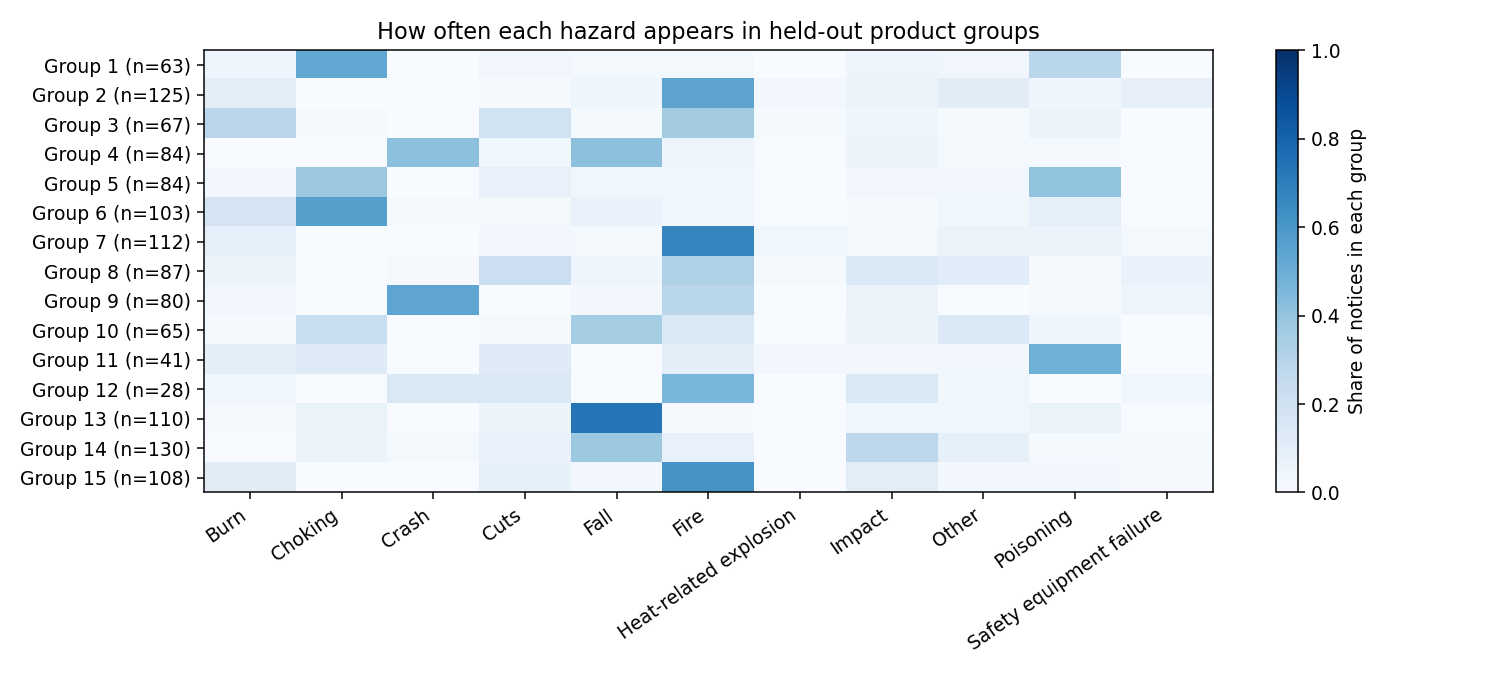

In [12]:
from io import BytesIO
from IPython.display import Image
import matplotlib.pyplot as plt

from sklearn.preprocessing import MultiLabelBinarizer

hazard_names = dict(zip(
    ("BURN", "CHOKING", "CRASH", "CUTS", "FALLING", "FIRE", "HEAT_RELATED_EXPLOSION",
     "IMPACT", "OTHER", "POISONING", "SAFETY_EQUIPMENT_MALFUNCTION"),
    ("Burn", "Choking", "Crash", "Cuts", "Fall", "Fire", "Heat-related explosion",
     "Impact", "Other", "Poisoning", "Safety equipment failure"),
))
hazard_encoder = MultiLabelBinarizer()
hazard_counts = hazard_encoder.fit_transform(dataset["hazard_classification"])
fit_hazards, held_hazards = hazard_counts[fit_rows], hazard_counts[held_rows]
fit_overall = fit_hazards.mean(axis=0)
held_overall = held_hazards.mean(axis=0)
centers = clusters.transform(fit_vectors)
examples, distribution_rows, row_keys = [], [], []
for group_id in range(1, clusters.n_clusters + 1):
    in_fit = fit_groups == group_id
    in_held = held_groups == group_id
    fit_counts = fit_hazards[in_fit].sum(axis=0)
    test_counts = held_hazards[in_held].sum(axis=0)
    eligible_hazards = np.flatnonzero(fit_counts >= 5)
    if not in_held.any() or not len(eligible_hazards):
        continue
    fit_rates = fit_counts / in_fit.sum()
    strongest = max(eligible_hazards, key=lambda h: fit_rates[h] - fit_overall[h])
    closest = np.flatnonzero(in_fit)
    closest = closest[np.argsort(centers[closest, group_id - 1], kind="stable")]
    names = dict.fromkeys(" ".join(product_fields["product_name"].loc[fit_rows[index]])
                          for index in closest)
    examples.append({
        "Cluster": group_id, "Example products": " / ".join(list(names)[:3]),
        "Overrepresented hazard label in fit set": hazard_names[hazard_encoder.classes_[strongest]],
        "All eligible notices": f"{fit_counts[strongest] + test_counts[strongest]}/{in_fit.sum() + in_held.sum()}",
        "Fit-set count": f"{fit_counts[strongest]}/{in_fit.sum()}",
        "Holdout count": f"{test_counts[strongest]}/{in_held.sum()}",
        "Within-cluster holdout share": test_counts[strongest] / in_held.sum(),
        "Overall holdout share": held_overall[strongest],
    })
    distribution_rows.append(test_counts / in_held.sum())
    row_keys.append(f"Group {group_id} (n={in_held.sum()})")

group_examples = pd.DataFrame(examples)
display(group_examples.round(3))
held_labels = labels_single.loc[held_rows].assign(
    group=held_groups,
    official_group=notice_groups.loc[held_rows],
).drop_duplicates("official_group")
rng = np.random.default_rng(SEED)
group_association = pd.DataFrame([
    {"Comparison": description, **cat_cat(held_labels, "group", column, rng)}
    for description, column in [("Product cluster vs. product category", "product_classification"),
                                ("Product cluster vs. hazard label", "hazard_classification")]
])
display(group_association.round(4))

joint = held_labels.dropna(subset=["product_classification", "hazard_classification"])
table = pd.crosstab(joint["group"], joint["hazard_classification"])
observed = table.to_numpy()
statistic, _, _, expected = chi2_contingency(observed, correction=False)
simulated = np.zeros((PERMUTATIONS, *observed.shape), dtype=int)
for _, block in joint.groupby("product_classification"):
    block_table = pd.crosstab(block["group"], block["hazard_classification"]).reindex(
        index=table.index, columns=table.columns, fill_value=0,
    ).to_numpy()
    simulated += random_table.rvs(block_table.sum(axis=1), block_table.sum(axis=0),
                                  size=PERMUTATIONS, random_state=rng)
draw_statistics = np.sum((simulated - expected) ** 2 / expected, axis=(1, 2))
within_category_p = (1 + (draw_statistics >= statistic - 1e-12).sum()) / (PERMUTATIONS + 1)
display(pd.DataFrame([{"Notices checked": len(joint), "Within-category permutation p": within_category_p}]))

matrix = np.vstack(distribution_rows)
fig, ax = plt.subplots(figsize=(11, 5))
image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(matrix.shape[1]), [hazard_names[h] for h in hazard_encoder.classes_],
              rotation=35, ha="right")
ax.set_yticks(range(len(row_keys)), row_keys)
ax.set_title("How often each hazard appears in held-out product groups")
fig.colorbar(image, ax=ax, label="Share of notices in each group")
fig.tight_layout()
plot_bytes = BytesIO()
fig.savefig(plot_bytes, format="png", dpi=135)
display(Image(data=plot_bytes.getvalue()))
plt.close(fig)

The bicycle-related cluster has the FALLING label on 35 of 84 held-out notices (41.7%). The overall holdout share is 16.8%. Cramér’s V for cluster versus hazard label is 0.409. The highest silhouette score is 0.125, so the clusters overlap; their label distributions still help prioritize related cases.